<Axes: xlabel='department_id', ylabel='aisle_count'>

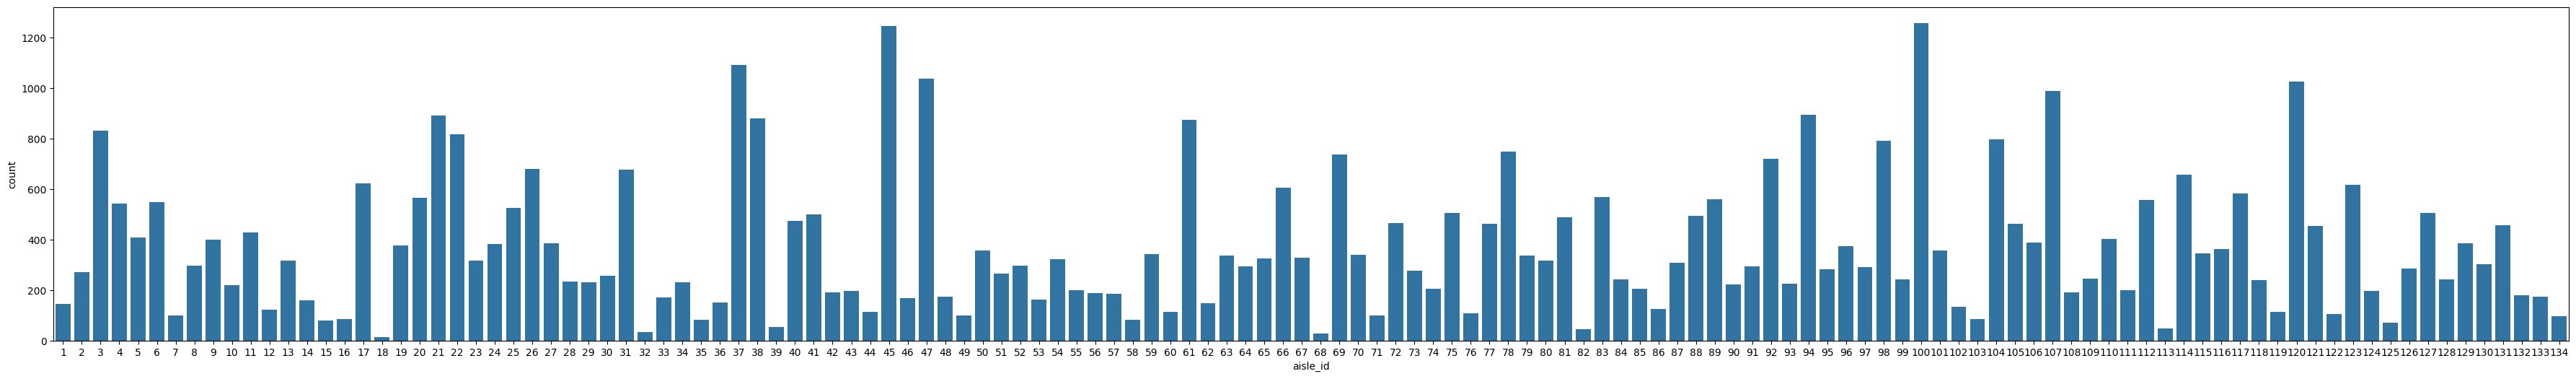

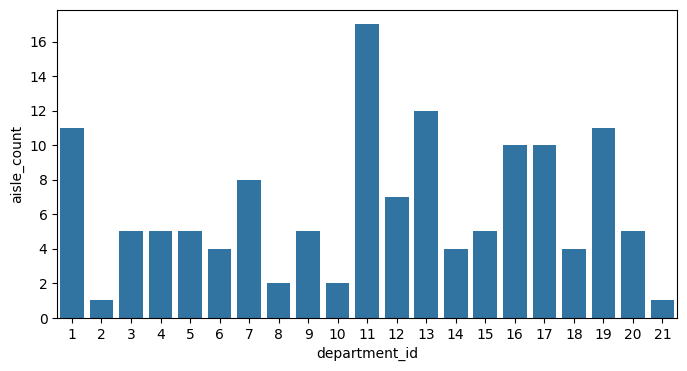

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


prodcut_data = pd.read_csv("products.csv", delimiter=",")

# nombre de produit/ailse

product_count = prodcut_data['aisle_id'].value_counts().reset_index()
product_count.columns = ['aisle_id', 'count']

plt.figure(figsize=(45, 6))

sns.barplot(data=product_count, x='aisle_id', y='count')

# nombre de aisle/department

aisle_count = prodcut_data.groupby('department_id')['aisle_id'].nunique().reset_index()
aisle_count.columns = ['department_id', 'aisle_count']

plt.figure(figsize=(8, 4))
sns.barplot(data=aisle_count, x='department_id', y='aisle_count')


In [ ]:
# visualisation
prodcut_data.head()

,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


In [ ]:
# nouveaux datasets 
orders_data = pd.read_csv("orders.csv", delimiter=",")
order_products_data = pd.read_csv("order_products.csv", delimiter=",")

order_products_data.head()

,order_id,product_id,add_to_cart_order,reordered
0,2,33120.0,1.0,1.0
1,2,28985.0,2.0,1.0
2,2,9327.0,3.0,0.0
3,2,45918.0,4.0,1.0
4,2,30035.0,5.0,0.0


In [ ]:
# cleanning
orders_data = orders_data.fillna(0)

orders_data.head()

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1.0,1.0,2.0,8.0,0.0
1,2398795,1.0,2.0,3.0,7.0,15.0
2,473747,1.0,3.0,3.0,12.0,21.0
3,2254736,1.0,4.0,4.0,7.0,29.0
4,431534,1.0,5.0,4.0,15.0,28.0


In [ ]:
# merge les deux datasets
order_hist_data = pd.merge(orders_data, order_products_data, left_on='order_id', right_on='order_id', how='left').drop('reordered', axis=1)
order_hist_data.head()

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order
0,2539329,1.0,1.0,2.0,8.0,0.0,196.0,1.0
1,2539329,1.0,1.0,2.0,8.0,0.0,14084.0,2.0
2,2539329,1.0,1.0,2.0,8.0,0.0,12427.0,3.0
3,2539329,1.0,1.0,2.0,8.0,0.0,26088.0,4.0
4,2539329,1.0,1.0,2.0,8.0,0.0,26405.0,5.0


In [ ]:
# change l'axe des infos 
order_hist_data['position'] = order_hist_data.groupby(['order_id', 'order_number', 'user_id']).cumcount() + 1

paniers = order_hist_data.set_index(['order_id', 'order_number', 'user_id', 'position'])['product_id'].unstack()

paniers = paniers.reset_index()

In [ ]:
# un peu plus de cleaning
paniers = paniers.astype('Int64')
paniers = paniers.fillna(0)

In [ ]:
# visualisation
paniers.head()

position,order_id,order_number,user_id,1,2,3,4,5,6,7,...,118,119,120,121,122,123,124,125,126,127
0,2,3,202279,33120,28985,9327,45918,30035,17794,40141,...,0,0,0,0,0,0,0,0,0,0
1,4,36,178520,46842,26434,39758,27761,10054,21351,22598,...,0,0,0,0,0,0,0,0,0,0
2,6,4,22352,40462,15873,41897,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,8,5,3107,23423,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,20,1,182912,35430,47485,7419,5112,33452,24852,42633,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# nombre d'artcile en fonction de l'order_id
def count_articles(order) :
    x = paniers[paniers['order_id'] == order].index[0]
    for i in range(127) :
        if paniers[x][i] == 0 :
            return f"nombre d'articles = {i-1}"
            

print(count_articles(6))

nombre d'articles = 2


In [ ]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

# copie donnees utiles
df_orders = order_hist_data[['order_id', 'product_id']].copy()

# suppr doublons
df_orders = df_orders.drop_duplicates()

# seuils filtrage
min_product_purchases = 5
min_order_size = 2

# comptage frequences
product_counts = df_orders['product_id'].value_counts()
order_counts = df_orders['order_id'].value_counts()

# recup items valides
valid_products = product_counts[product_counts >= min_product_purchases].index
valid_orders = order_counts[order_counts >= min_order_size].index

# filtrage dataset
df_clean = df_orders[df_orders['product_id'].isin(valid_products) & 
                     df_orders['order_id'].isin(valid_orders)]

# conversion categorielle
product_c = pd.Categorical(df_clean['product_id'])
order_c = pd.Categorical(df_clean['order_id'])

# prep donnees matrice
row = product_c.codes
col = order_c.codes
data = np.ones(len(df_clean))

# creation matrice creuse
item_matrix = csr_matrix((data, (row, col)), shape=(len(product_c.categories), len(order_c.categories)))

# init modele knn
knn_model = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=6)

# entrainement
knn_model.fit(item_matrix)


# fonction reco
def recommander_produits(product_id, n_recommandations=5):

    # verif existence
    if product_id not in product_c.categories:
        return "Produit inconnu ou pas assez de données pour ce produit."
    
    # index produit
    product_idx = product_c.categories.get_loc(product_id)
    
    # extraction vecteur
    product_vector = item_matrix[product_idx].reshape(1, -1)
    
    # recherche voisins
    distances, indices = knn_model.kneighbors(product_vector, n_neighbors=n_recommandations + 1)
    
    # formatage resultats
    recommandations = []
    
    for i in range(1, len(distances.flatten())):
        idx_voisin = indices.flatten()[i]
        id_produit_voisin = product_c.categories[idx_voisin]
        distance = distances.flatten()[i]
        
        # calcul similarite
        similarite = 1 - distance 
        recommandations.append((id_produit_voisin, round(similarite, 4)))
        
    return recommandations

In [ ]:
# phase de test
print("Produits recommandés pour l'article 33120 :")
recs = recommander_produits(33120, n_recommandations=5)
for prod, score in recs:
    print(f"Product ID: {prod} | Similarité: {score}")

Produits recommandés avec l'article 33120 :
Product ID: 21903.0 | Similarité: 0.0648
Product ID: 13176.0 | Similarité: 0.0424
Product ID: 47209.0 | Similarité: 0.0421
Product ID: 21137.0 | Similarité: 0.0367
Product ID: 47766.0 | Similarité: 0.0361


In [ ]:
# fonction calcul precision
def calculer_precision_recommandation(vrais_articles, articles_recommandes):
   
    # conversion en sets
    vrais_set = set(vrais_articles)
    reco_set = set(articles_recommandes)
    
    # nbr elements communs (hits)
    hits = len(vrais_set.intersection(reco_set))
    
    # ratio precision
    precision = hits / len(reco_set) if len(reco_set) > 0 else 0
    
    return precision


# data test (vrais achats)
vrais_achats = [28985, 9327, 45918] 

# data test (predictions knn)
recommandations_knn = [28985, 11111, 22222, 45918, 33333]

# calcul score
score = calculer_precision_recommandation(vrais_achats, recommandations_knn)

# affichage
print(f"Précision du modèle : {score}")

Précision du modèle : 0.4
